# Network Traffic Prediction Using Regression 
**Dataset:** `https://archive.ics.uci.edu/dataset/942/rt-iot2022`

This notebook predicts **`flow_duration`** using regression. 

## 1. Install libraries

In [1]:
%pip install pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries are ready!")

Libraries are ready!


## 3. Load the dataset

In [3]:
df = pd.read_csv("RT_IOT2022_5000_20pct_messy.csv")

print("Dataset loaded!")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded!
Rows and columns: (5000, 85)


,Record_ID,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,1,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,29729182.958603,29729182.958603,29729182.958603,29729182.958603,0.0,64240,26847,502,MQTT_Publish
1,2,51143,1883,tcp,mqtt,31.88358400000001,9,5,3,3,...,0.0,29855277.061462,29855277.061462,29855277.061462,29855277.061462,0.0,64240,26847,502,MQTT_Publish
2,3,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,29842149.019241,29842149.019241,29842149.019241,29842149.019241,0.0,64240,26847,502,MQTT_Publish
3,4,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,29913774.967194,29913774.967194,29913774.967194,29913774.967194,0.0,64240,26847,502,MQTT_Publish
4,5,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,29814704.89502,29814704.89502,29814704.89502,29814704.89502,0.0,64240,26847,502,MQTT_Publish


## 4. Check the dataset

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Column names:
['Record_ID', 'id.orig_p', 'id.resp_p', 'proto', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.min', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'flow_pkts_payload.std', 'fwd_iat.min', 'fwd_iat.max'

## 5. Remove duplicate rows and clean column names

In [5]:
df.columns = df.columns.str.strip()
df = df.drop_duplicates()

print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 5000


## 6. Clean the messy data

The numeric columns are converted into numbers. If a value contains messy text or special symbols and cannot be changed into a number, it becomes a missing value. The model will fill missing input values in a later step.

In [6]:
df["flow_duration"] = pd.to_numeric(df["flow_duration"], errors="coerce")
df = df.dropna(subset=["flow_duration"])
df = df.replace([float("inf"), float("-inf")], float("nan"))

print("Rows after cleaning target:", len(df))
print("Missing flow_duration values:", df["flow_duration"].isnull().sum())
display(df[["flow_duration"]].head())

Rows after cleaning target: 4976
Missing flow_duration values: 0


,flow_duration
0,32.011598
1,31.883584
2,32.124053
3,31.961063
4,31.902362


## 7. Choose input features and target

- **Target (y):** `flow_duration` — the number we want to predict.
- **Inputs (X):** numeric network measurements.
- We do not use `Record_ID` because it is only an ID.
- We do not use `Attack_type` because it is a category, not a number to predict.
- We remove `flow_iat.tot` because it measures total flow inter-arrival time and can give the model information very close to the target.

In [7]:
for column in df.columns:
    if column != "flow_duration":
        df[column] = pd.to_numeric(df[column], errors="coerce")

X = df.drop(
    columns=["flow_duration", "Record_ID", "Attack_type", "flow_iat.tot"],
    errors="ignore"
)
y = df["flow_duration"]

# Remove columns that have no numeric values at all
X = X.dropna(axis=1, how="all")

print("Number of input columns:", X.shape[1])
print("Number of rows:", X.shape[0])
display(X.head())

Number of input columns: 79
Number of rows: 4976


,id.orig_p,id.resp_p,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,...,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size
0,38667.0,1883.0,9.0,5.0,3.0,3.0,0.281148,0.156193,0.437341,0.555556,...,2.282415e+06,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240.0,26847.0,502.0
1,51143.0,1883.0,9.0,5.0,3.0,3.0,0.282277,0.156821,0.439097,0.555556,...,2.028307e+06,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240.0,26847.0,502.0
2,44761.0,1883.0,9.0,5.0,3.0,3.0,0.280164,0.155647,0.435811,0.555556,...,2.281904e+06,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240.0,26847.0,502.0
3,60893.0,1883.0,9.0,5.0,3.0,3.0,0.281593,0.156440,0.438033,0.555556,...,2.047288e+06,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240.0,26847.0,502.0
4,51087.0,1883.0,9.0,5.0,3.0,3.0,0.282111,0.156728,0.438839,0.555556,...,2.087657e+06,0.0,2.981470e+07,2.981470e+07,2.981470e+07,2.981470e+07,0.0,64240.0,26847.0,502.0


## 8. Split data into training and testing sets
80% of the data is used to train the model. The other 20% is used to test it.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 3980
Testing rows: 996


## 9. Fill missing input values
We use the middle value (median) from the training data to fill missing values.

In [9]:
fill_missing = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    fill_missing.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    fill_missing.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing input values filled!")

Missing input values filled!


## 10. Train Linear Regression

In [14]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print("Linear Regression training completed!")

Linear Regression training completed!


## 11. Train Random Forest Regression

In [13]:
forest_model = RandomForestRegressor(
    n_estimators=50,
    random_state=42
)
forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


## 12. Make predictions

In [15]:
linear_predictions = linear_model.predict(X_test)
forest_predictions = forest_model.predict(X_test)

print("First 5 actual flow durations:")
print(y_test.head().tolist())

print("\nFirst 5 Random Forest predictions:")
print(forest_predictions[:5].tolist())

First 5 actual flow durations:
[61.97235500000001, 32.049269, 20.907408, 112.605257, 30.048103]

First 5 Random Forest predictions:
[61.97228437999999, 32.049032140000016, 20.911777159999996, 87.87490028000002, 30.051692159999988]


## 13. Check model results

- **MAE:** average size of the prediction error (lower is better).
- **MSE:** average squared error (lower is better).
- **RMSE:** error shown in the target's units (lower is better).
- **R²:** closer to 1 is generally better.

In [16]:
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_mse = mean_squared_error(y_test, linear_predictions)
linear_rmse = linear_mse ** 0.5
linear_r2 = r2_score(y_test, linear_predictions)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_mse = mean_squared_error(y_test, forest_predictions)
forest_rmse = forest_mse ** 0.5
forest_r2 = r2_score(y_test, forest_predictions)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, forest_mae],
    "MSE": [linear_mse, forest_mse],
    "RMSE": [linear_rmse, forest_rmse],
    "R2 Score": [linear_r2, forest_r2]
})

display(results.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.3381,1.0692,1.034,0.9986
1,Random Forest,0.1494,2.1432,1.464,0.9972


## 14. Compare the models with a graph

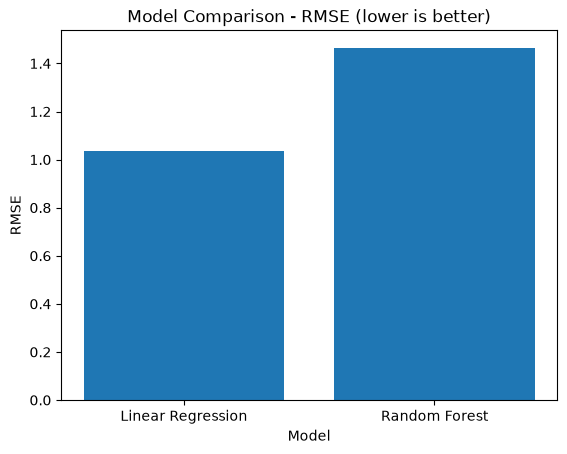

In [17]:
plt.bar(results["Model"], results["RMSE"])
plt.title("Model Comparison - RMSE (lower is better)")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.show()

## 15. Plot actual and predicted values

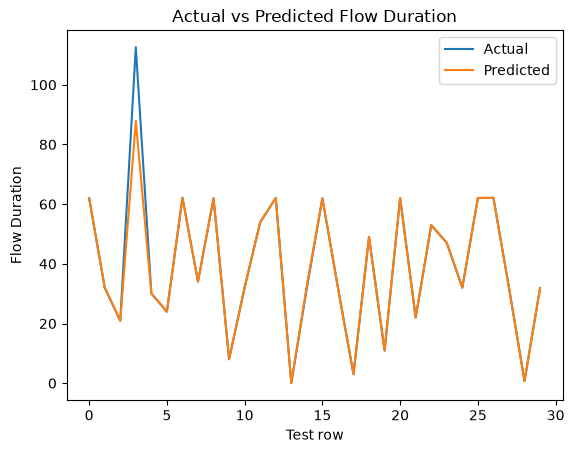

In [18]:
plt.plot(y_test.iloc[:30].to_numpy(), label="Actual")
plt.plot(forest_predictions[:30], label="Predicted")
plt.title("Actual vs Predicted Flow Duration")
plt.xlabel("Test row")
plt.ylabel("Flow Duration")
plt.legend()
plt.show()

## 16. Show the first 10 predictions

In [19]:
prediction_table = pd.DataFrame({
    "Actual Flow Duration": y_test.to_numpy(),
    "Predicted Flow Duration": forest_predictions
})

display(prediction_table.head(10).round(4))

,Actual Flow Duration,Predicted Flow Duration
0,61.9724,61.9723
1,32.0493,32.0490
2,20.9074,20.9118
3,112.6053,87.8749
4,30.0481,30.0517
5,23.9745,23.9723
6,62.1248,62.1262
7,34.0274,34.0366
8,61.9669,61.9669
9,8.0233,8.0333


## 17. Final result

In [20]:
best_model = results.loc[results["RMSE"].idxmin(), "Model"]

print("PROJECT: Network Traffic Prediction Using Regression")
print("Target predicted: flow_duration")
print("Best model based on lower RMSE:", best_model)
print("\nModel comparison:")
display(results.round(4))

PROJECT: Network Traffic Prediction Using Regression
Target predicted: flow_duration
Best model based on lower RMSE: Linear Regression

Model comparison:


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.3381,1.0692,1.034,0.9986
1,Random Forest,0.1494,2.1432,1.464,0.9972


## Conclusion

This project uses regression to predict network flow duration. The CSV is loaded, duplicate rows are removed, messy numeric values are cleaned, and missing input values are filled. Linear Regression and Random Forest Regression are trained and compared using MAE, MSE, RMSE, and R².
